# plot_g6vsSSPunc — GeoMIP modeling variance: aerosols vs SSP/GHG

Python port of `plot_g6vsSSPunc.m`. For each IPCC-WGI region it plots the
fraction of the modeling variance driven by the SSP/GHG response
(`ta_var_ssp`) relative to the combined aerosol + SSP variance, for surface
temperature (`tas`) against precipitation (`pr`), coloured by continental
group. Faithful 1:1 translation; only the plotting back-end differs.

The two `*_regions1_std` inputs are *created by scripts in this folder*
(`plot_HS_GeoMIP`, `plot_HSpr_GeoMIP`), so they are read from the
Python-native `data_py/*.npz` rather than `.mat`.

In [1]:
import sys
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, shaperead

regions = shaperead("IPCC-WGI-reference-regions-v4.shx")   # loaded as in MATLAB

In [2]:
t = mu.load_npz("tas_regions1_std")          # 3-var file from plot_HS_GeoMIP
tas_r1_sol = np.asarray(t["ta_var_ssp"]).ravel()
tas_r1_sulf = np.asarray(t["ta_var_sulf"]).ravel()

p_ = mu.load_npz("pr_regions1_std")          # 3-var file from plot_HSpr_GeoMIP
pr_r1_sol = np.asarray(p_["ta_var_ssp"]).ravel()
pr_r1_sulf = np.asarray(p_["ta_var_sulf"]).ravel()

pr1 = pr_r1_sol / (pr_r1_sol + pr_r1_sulf) * 100
tas1 = tas_r1_sol / (tas_r1_sol + tas_r1_sulf) * 100

## Scatter by continental group
`col_regs` are the MATLAB 1-based region-index groups, converted to 0-based.

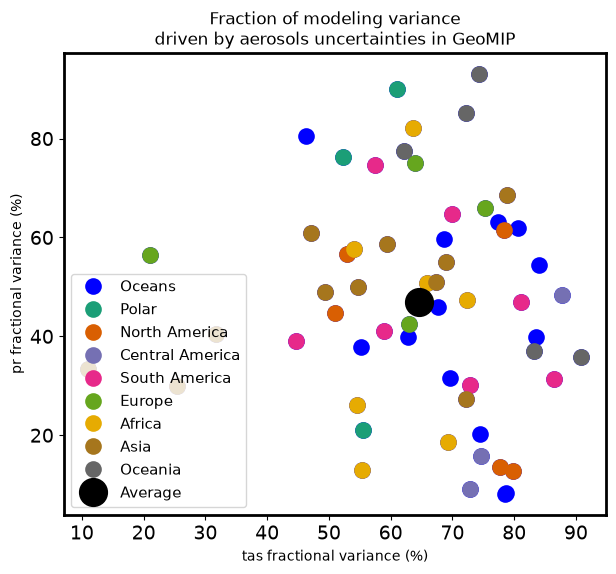

In [3]:
fc = brewermap(8, "Dark2")
# MATLAB col_regs (1-based) -> 0-based index lists
col_regs = [
    [0, 44, 45],            # [1 45:46]
    [1, 2, 3, 4, 5],        # [2:6]
    [6, 7, 8],              # [7:9]
    [9, 10, 11, 12, 13, 14, 15],   # [10:16]
    [16, 17, 18, 19],       # [17:20]
    [21, 22, 23, 24, 25, 26, 27],  # [22:28]
    list(range(28, 39)),    # [29:39]
    [39, 40, 41, 42, 43],   # [40:44]
]
regions_n = ["Oceans", "Polar", "North America", "Central America",
             "South America", "Europe", "Africa", "Asia", "Oceania", "Average"]

fig, ax = plt.subplots(figsize=(7, 6))
handles = []
handles.append(ax.plot(tas1, pr1, "o", markerfacecolor="b",
                       markeredgecolor="none", markersize=12)[0])
for i in range(8):
    handles.append(ax.plot(tas1[col_regs[i]], pr1[col_regs[i]], "o",
                           markerfacecolor=fc[i], markeredgecolor="none",
                           markersize=12)[0])
handles.append(ax.plot(np.mean(tas1), np.mean(pr1), "o", markerfacecolor="k",
                       markeredgecolor="k", markersize=20)[0])

ax.legend(handles, regions_n, loc="lower left", fontsize=11)
ax.set_xlabel("tas fractional variance (%)")
ax.set_ylabel("pr fractional variance (%)")
ax.set_title("Fraction of modeling variance\ndriven by aerosols uncertainties in GeoMIP")
for s in ax.spines.values():
    s.set_linewidth(2)
ax.tick_params(labelsize=14)
plt.show()

## Reported summary statistics (as `disp(...)` in the MATLAB script)

In [4]:
print((np.mean(tas1) - 50) / (100 - np.mean(tas1)) * 100)
print((np.mean(pr1) - 50) / (100 - np.mean(pr1)) * 100)

xx = np.full(8, np.nan); tt = np.full(8, np.nan); prr = np.full(8, np.nan)
for i in range(1, 8):    # MATLAB for i=2:8 (1-based) -> groups index 1..7
    xx[i] = np.mean(tas1[col_regs[i]])
    tt[i] = (np.mean(tas1[col_regs[i]]) - 50) / (100 - np.mean(tas1[col_regs[i]])) * 100
    prr[i] = np.mean(pr1[col_regs[i]] - 50) / (100 - np.mean(pr1[col_regs[i]])) * 100
print("group tas excess (%):", np.round(tt, 1))

41.43430337497035
-5.92129766621458
group tas excess (%): [  nan  56.1 131.6  52.9  13.2  32.1   3.  113.3]


Original MATLAB writes `GeoMIP_uncertainties_ssp.eps`. We save the figure to
`py_outputs/` (the original `.eps` is left untouched).

In [5]:
import os
os.makedirs("py_outputs", exist_ok=True)
fig.savefig("py_outputs/GeoMIP_uncertainties_ssp.png", dpi=300, bbox_inches="tight")
print("saved py_outputs/GeoMIP_uncertainties_ssp.png")

saved py_outputs/GeoMIP_uncertainties_ssp.png
